# Proyecto Melbourne Housing · Validación cruzada y regularización

Respondemos a las preguntas del `README.md` con **regresión lineal múltiple** y sus versiones regularizadas, **Ridge** y **Lasso**, evaluadas con **validación cruzada K-Fold** (S04).

Reglas de la S04 que seguimos:
- La validación cruzada se hace **dentro** del entrenamiento; el test se usa **una sola vez**, al final.
- Se reporta la **media y la dispersión** de los folds, no solo la media.
- Se **escala** antes de regularizar, y el `StandardScaler` se ajusta **solo con train** (ejercicio 3).
- **5 columnas de ruido** como control: Lasso debe ponerlas a cero (ejercicio 1).

In [1]:
# Librerías de siempre
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

# Herramientas de scikit-learn
from sklearn.model_selection import train_test_split, cross_val_score, cross_validate, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy import stats                  # para el contraste de significación

sns.set_theme(style="whitegrid")

## 1. Datos

`melbourne_limpio.csv` ya está limpio y sin nulos (generado por `src/read_csv.py`). Las columnas `*_imputado` indican qué valores eran huecos.

In [2]:
# El notebook está en models/, así que subimos una carpeta para llegar a datasets/
BASE = Path.cwd().parent
df = pd.read_csv(BASE / "datasets" / "melbourne_limpio.csv")

# Columnas de texto: habrá que convertirlas a números para los modelos lineales
CATEGORICAS = ["Type", "Suburb", "Method", "SellerG"]
print(f"Dimensiones: {df.shape[0]} viviendas x {df.shape[1]} columnas")
print(df.head())

Dimensiones: 27246 viviendas x 15 columnas
   Rooms  Bathroom  Car  Landsize  BuildingArea  YearBuilt  Distance  \
0    2.0       1.0  1.0     202.0          96.0     1900.0       2.5   
1    2.0       1.0  0.0     156.0          79.0     1900.0       2.5   
2    3.0       2.0  0.0     134.0         150.0     1900.0       2.5   
3    3.0       2.0  1.0      94.0         130.0     1900.0       2.5   
4    4.0       1.0  2.0     120.0         142.0     2014.0       2.5   

   BuildingArea_imputado  Landsize_imputado  Bathroom_imputado Type  \
0                      1                  0                  0    h   
1                      0                  0                  0    h   
2                      0                  0                  0    h   
3                      1                  0                  0    h   
4                      0                  0                  0    h   

       Suburb Method SellerG      Price  
0  Abbotsford      S  Biggin  1480000.0  
1  Abbotsford

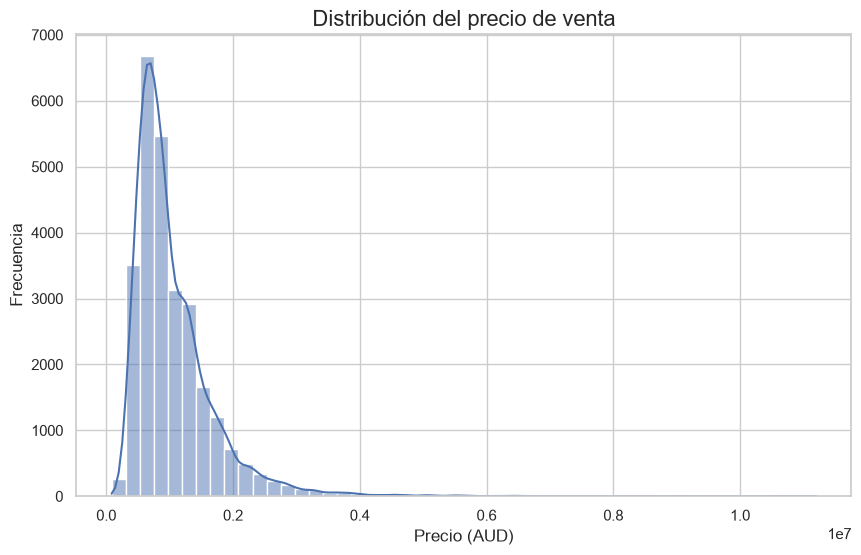

Mediana: 870,000 AUD   Máximo: 11,200,000 AUD   Asimetría: 2.59


In [3]:
# Distribución del precio: si está sesgada, el RMSE lo dominarán las casas caras
plt.figure(figsize=(10, 6))
sns.histplot(df["Price"], kde=True, bins=50)
plt.title("Distribución del precio de venta", fontsize=16)
plt.xlabel("Precio (AUD)")
plt.ylabel("Frecuencia")
plt.show()

print(f"Mediana: {df['Price'].median():,.0f} AUD   "
      f"Máximo: {df['Price'].max():,.0f} AUD   "
      f"Asimetría: {df['Price'].skew():.2f}")

## Preparación de los datos

1. **Texto → columnas 0/1** con `get_dummies` (`drop_first=True`, la regresión lineal lo necesita).
2. **Separar `X` e `y`.**
3. **Dividir en train y test primero**, y después **escalar ajustando el `StandardScaler` solo con train** (como en el ejercicio 3).
4. Comprobar la **relación filas/columnas**: nos dirá si la regularización puede aportar algo.

In [4]:
# 1. Categóricas -> columnas 0/1
#    drop_first=True quita una categoría de cada columna: queda como referencia (si Type_t = 0 y Type_u = 0, es una casa)
df_modelo = pd.get_dummies(df, columns=CATEGORICAS, drop_first=True, dtype=int)

# 2. Separar X e y
X = df_modelo.drop("Price", axis=1)
y = df_modelo["Price"]
columnas = list(X.columns)   # guardamos los nombres para leer los coeficientes más adelante

# 3. PRIMERO se divide en train y test (con datos sin escalar)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# El scaler se ajusta SOLO con train y se aplica a ambos
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(f"Entrenamiento: {X_train_s.shape[0]} viviendas")
print(f"Prueba:        {X_test_s.shape[0]} viviendas")
print(f"Columnas:      {X_train_s.shape[1]}")

# 4. Relación filas/columnas: cuantas más filas por columna, menos aporta la regularización (ejercicio 3)
ratio = X_train_s.shape[0] / X_train_s.shape[1]
print(f"\nRelación filas/columnas en entrenamiento: {ratio:.0f} a 1")

Entrenamiento: 21796 viviendas
Prueba:        5450 viviendas
Columnas:      707

Relación filas/columnas en entrenamiento: 31 a 1


## 2. Modelos

Misma rejilla de `alphas` en escala logarítmica para Ridge y Lasso (lo que importa es el orden de magnitud). `LassoCV` y `RidgeCV` eligen `alpha` con validación cruzada interna.

In [5]:
# 13 valores de alpha entre 0,000001 y 1.000.000 (escala logarítmica)
alphas = np.logspace(-6, 6, 13)

# Diccionario con los modelos: así podemos recorrerlos todos con un bucle
modelos = {
    "LinearRegression": LinearRegression(),
    "RidgeCV": RidgeCV(alphas=alphas, scoring="neg_mean_squared_error"),       # no acepta random_state ni necesita cv
    "LassoCV": LassoCV(alphas=alphas, cv=5, random_state=42, max_iter=10000),   # max_iter alto para que converja
}

## 1.1 · Predice el precio medio de una vivienda

### Elección del número de folds

Antes de poner 5 por costumbre: media y dispersión del RMSE de la regresión lineal según K, frente al tiempo. Más folds = más entrenamientos (más coste) y folds de validación más pequeños (más ruidosos).

In [6]:
import time

filas_k = []
for k in (3, 5, 10, 20):
    t0 = time.time()   # cronómetro: más folds = más entrenamientos = más tiempo
    scores = cross_val_score(LinearRegression(), X_train_s, y_train,
                             cv=KFold(k, shuffle=True, random_state=42), scoring="neg_mean_squared_error")
    rmse_k = np.sqrt(-scores)   # el error viene en negativo: le cambiamos el signo antes de la raíz
    filas_k.append({"K": k, "RMSE medio": rmse_k.mean(), "Desv. típica": rmse_k.std(),
                    "Desv./media (%)": 100 * rmse_k.std() / rmse_k.mean(), "Tiempo (s)": time.time() - t0})
pd.DataFrame(filas_k).set_index("K").round(2)

,RMSE medio,Desv. típica,Desv./media (%),Tiempo (s)
K,,,,
3,369334.89,21977.24,5.95,3.47
5,367237.33,25544.67,6.96,5.32
10,367492.36,29792.93,8.11,14.23
20,366441.59,36877.70,10.06,55.47


### Validación cruzada de los tres modelos

Las **mismas particiones** (`KFold` con semilla fija) para todos, así las diferencias entre modelos no se deben a que les tocaron filas distintas. Como scikit-learn siempre maximiza, las métricas de error vienen en negativo: hay que cambiarles el signo.

In [7]:
# Las mismas 5 particiones para todos los modelos (semilla fija)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# cross_validate permite pedir varias métricas a la vez (cross_val_score solo una)
scoring = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}

# folds guarda, para cada modelo, el valor de cada métrica en cada fold
folds = {}
for nombre, modelo in modelos.items():
    res = cross_validate(modelo, X_train_s, y_train, cv=kf, scoring=scoring)   # solo train: el test no se toca
    folds[nombre] = {"RMSE": -res["test_RMSE"], "MAE": -res["test_MAE"], "R2": res["test_R2"]}


# RMSE de cada fold: si bailan mucho, la estimación es poco fiable
for nombre, f in folds.items():
    print(f"----- {nombre} -----")
    print("RMSE de cada fold: " + "  ".join(f"{r:,.0f}" for r in f["RMSE"]))
    print(f"RMSE promedio (CV): {f['RMSE'].mean():,.0f}   Desviación típica (CV): {f['RMSE'].std():,.0f}\n")

# Tabla resumen: media y desviación típica de cada métrica
resumen = pd.DataFrame({nombre: {f"{m} media": f[m].mean() for m in f} | {f"{m} desv.": f[m].std() for m in f}
                        for nombre, f in folds.items()}).T
resumen[["RMSE media", "RMSE desv.", "MAE media", "MAE desv.", "R2 media", "R2 desv."]].round(3)

c:\Users\migue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.887169e+12, tolerance: 5.734e+11
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\migue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.103624e+12, tolerance: 5.578e+11
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\migue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iteration

----- LinearRegression -----
RMSE de cada fold: 409,252  370,766  370,515  354,711  330,943
RMSE promedio (CV): 367,237   Desviación típica (CV): 25,545

----- RidgeCV -----
RMSE de cada fold: 408,570  369,902  369,910  353,474  330,330
RMSE promedio (CV): 366,437   Desviación típica (CV): 25,577

----- LassoCV -----
RMSE de cada fold: 409,027  369,594  369,206  352,647  329,729
RMSE promedio (CV): 366,040   Desviación típica (CV): 25,955



,RMSE media,RMSE desv.,MAE media,MAE desv.,R2 media,R2 desv.
LinearRegression,367237.332,25544.667,230896.591,4287.404,0.676,0.018
RidgeCV,366437.209,25577.228,229951.971,4216.759,0.677,0.019
LassoCV,366040.499,25955.303,228345.213,4285.924,0.678,0.019


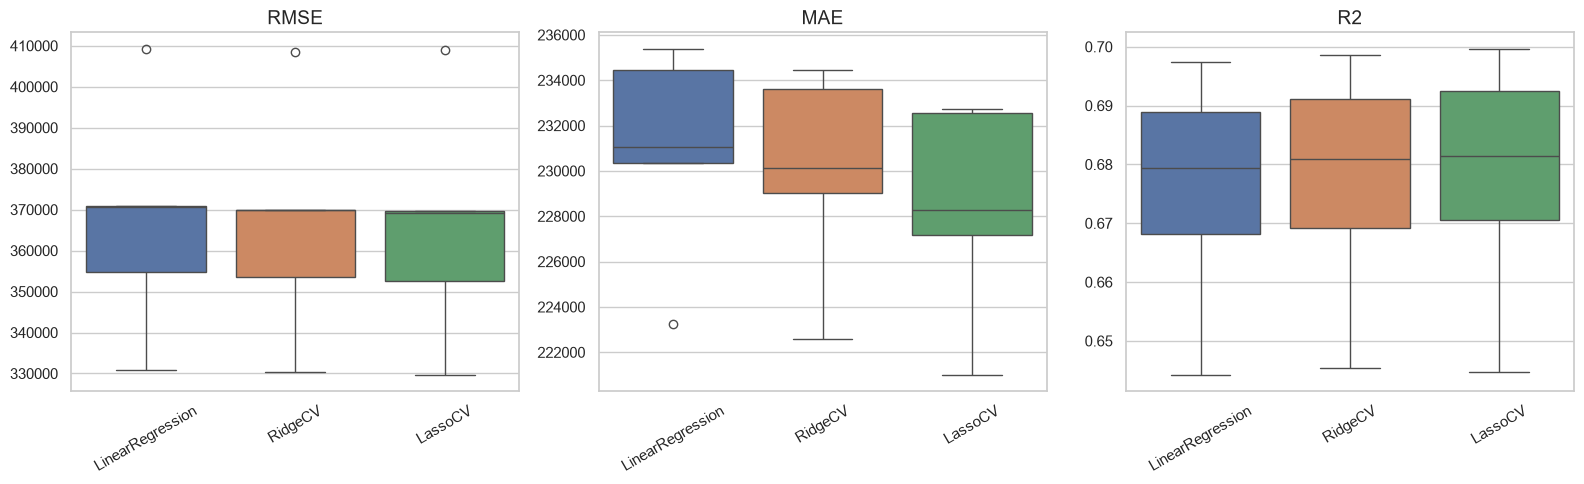

In [8]:
# Un boxplot por métrica: la altura de cada caja es la dispersión entre folds
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for i, m in enumerate(["RMSE", "MAE", "R2"]):
    sns.boxplot(data=pd.DataFrame({n: f[m] for n, f in folds.items()}), ax=ax[i])
    ax[i].set_title(m, fontsize=14)
    ax[i].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

### ¿Las diferencias son significativas o se deben al azar?

Comparamos fold a fold (son las mismas particiones). Si la diferencia media entre dos modelos es pequeña frente a la dispersión entre folds, puede ser azar.

Una t pareada normal se pasa de optimista, porque los folds comparten filas de entrenamiento. Usamos la **t corregida** (Nadeau y Bengio), que infla la varianza para tenerlo en cuenta.

In [9]:
from itertools import combinations

def t_corregida(a, b, n_train, n_test):
    d = np.asarray(a) - np.asarray(b)   # diferencia fold a fold entre los dos modelos
    k = len(d)
    # El término n_test / n_train infla la varianza porque los folds comparten filas
    t = d.mean() / np.sqrt((1 / k + n_test / n_train) * d.var(ddof=1))
    return t, 2 * stats.t.sf(abs(t), df=k - 1)   # devuelve t y su p-valor (dos colas)

# Tamaño de cada fold de validación y de entrenamiento
n_test_fold = len(X_train_s) // 5
n_train_fold = len(X_train_s) - n_test_fold
pares = list(combinations(folds, 2))   # todas las parejas de modelos

filas = []
for a, b in pares:
    d = folds[a]["RMSE"] - folds[b]["RMSE"]
    t, p = t_corregida(folds[a]["RMSE"], folds[b]["RMSE"], n_train_fold, n_test_fold)
    filas.append({"Comparación": f"{a} vs {b}", "Dif. RMSE media": d.mean(), "Desv. dif.": d.std(),
                  "Folds que gana el 1º (de 5)": int((d < 0).sum()),
                  "p": p, "p (Bonferroni)": min(1.0, p * len(pares))})   # Bonferroni: comparamos muchos pares
contrastes = pd.DataFrame(filas).set_index("Comparación")
contrastes["¿Significativa (5 %)?"] = contrastes["p (Bonferroni)"] < 0.05
contrastes.round(4)

,Dif. RMSE media,Desv. dif.,Folds que gana el 1º (de 5),p,p (Bonferroni),¿Significativa (5 %)?
Comparación,,,,,,
LinearRegression vs RidgeCV,800.1224,237.4662,0,0.0109,0.0327,True
LinearRegression vs LassoCV,1196.8332,584.5979,0,0.0525,0.1574,False
RidgeCV vs LassoCV,396.7108,460.0710,1,0.3143,0.9430,False


### Y ahora sí, el conjunto de test, una sola vez

In [10]:
# Entrenamos con todo el train y predecimos el test (una sola vez)
pred_test = {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train_s, y_train)
    pred_test[nombre] = modelo.predict(X_test_s)

test = pd.DataFrame({nombre: {"RMSE test": np.sqrt(mean_squared_error(y_test, p)),
                              "MAE test": mean_absolute_error(y_test, p),
                              "R2 test": r2_score(y_test, p),
                              "Precio medio predicho": p.mean()}
                     for nombre, p in pred_test.items()}).T
print(f"Precio medio real (test): {y_test.mean():,.0f} AUD")
print(f"Alpha Ridge: {modelos['RidgeCV'].alpha_:,.6f}   Alpha Lasso: {modelos['LassoCV'].alpha_:,.6f}")
test.round(3)

c:\Users\migue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.237902e+13, tolerance: 7.446e+11
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\migue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.064390e+13, tolerance: 7.157e+11
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\migue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iteration

Precio medio real (test): 1,046,728 AUD
Alpha Ridge: 100.000000   Alpha Lasso: 1,000.000000


,RMSE test,MAE test,R2 test,Precio medio predicho
LinearRegression,342652.097,223730.561,0.701,1042388.744
RidgeCV,342481.116,223462.105,0.702,1043125.403
LassoCV,342261.711,221769.120,0.702,1043669.411


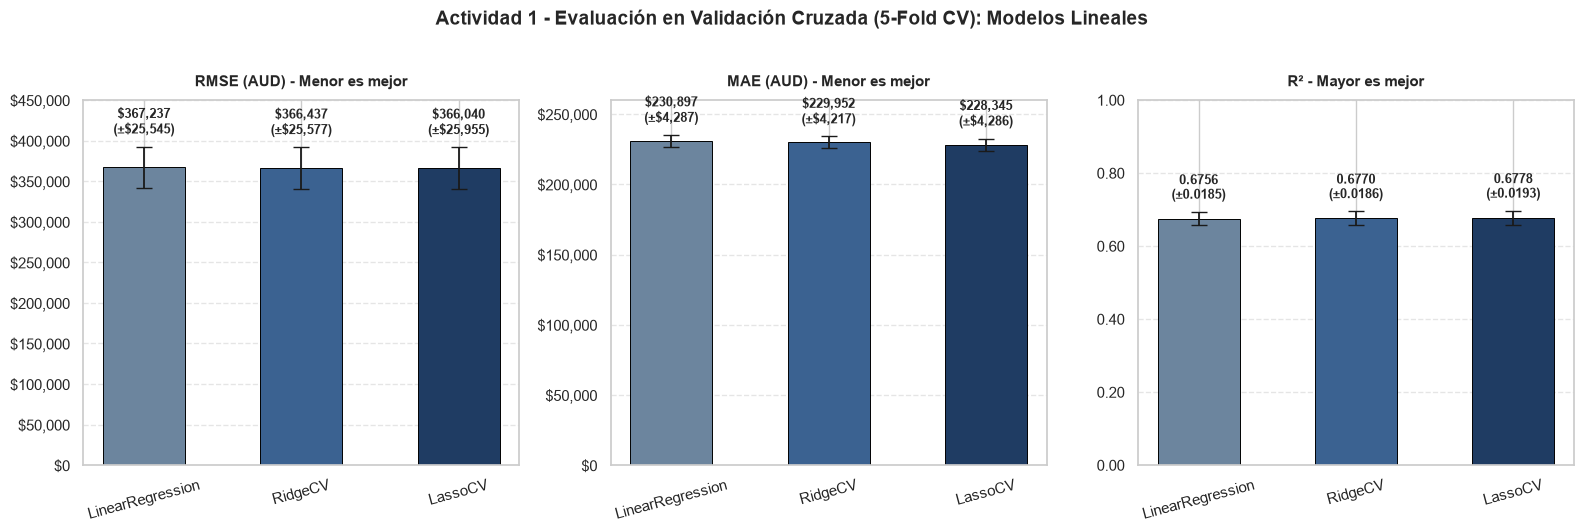

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# --- GRAFICO UNIFICADO ACTIVIDAD 1: COMPARATIVA DE METRICAS (5-FOLD CV) ---
nombres_modelos = list(folds.keys())
colores = ["#6c859e", "#3b6291", "#1f3c63"]

metricas_cfg = [
    ("RMSE", "RMSE (AUD) - Menor es mejor", (0, 450_000), True),
    ("MAE",  "MAE (AUD) - Menor es mejor",  (0, 260_000), True),
    ("R2",   "R² - Mayor es mejor",         (0, 1.0),     False),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
fig.suptitle("Actividad 1 - Evaluación en Validación Cruzada (5-Fold CV): Modelos Lineales", fontsize=14, fontweight="bold", y=1.02)

for ax, (clave, titulo, ylim, es_dinero) in zip(axes, metricas_cfg):
    medias = [np.mean(folds[m][clave]) for m in nombres_modelos]
    desvs  = [np.std(folds[m][clave])  for m in nombres_modelos]

    barras = ax.bar(nombres_modelos, medias, yerr=desvs, capsize=6, color=colores, width=0.52, edgecolor="black", linewidth=0.7, error_kw={"elinewidth": 1.3})

    ax.set_title(titulo, fontsize=11, fontweight="bold", pad=10)
    ax.set_ylim(ylim)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", rotation=15)

    if es_dinero:
        ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
    else:
        ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:.2f}"))

    for barra, media, desv in zip(barras, medias, desvs):
        texto = f"${media:,.0f}\n(±${desv:,.0f})" if es_dinero else f"{media:.4f}\n(±{desv:.4f})"
        offset = (ylim[1] * 0.025)
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            media + desv + offset,
            texto,
            ha="center", va="bottom", fontsize=9, fontweight="bold"
        )

plt.tight_layout()
plt.show()

## 1.2 · ¿Qué características encarecen una vivienda?

In [11]:
# 5 columnas de ruido (misma semilla que en clase, así el experimento es reproducible)
np.random.seed(42)
X_train_r = np.hstack((X_train_s, np.random.rand(X_train_s.shape[0], 5)))
X_test_r = np.hstack((X_test_s, np.random.rand(X_test_s.shape[0], 5)))
columnas_r = columnas + [f"ruido_{i + 1}" for i in range(5)]

# Lasso y Ridge entrenados con el ruido incluido
lasso_cv = LassoCV(alphas=alphas, cv=5, random_state=42, max_iter=10000).fit(X_train_r, y_train)
ridge_cv = RidgeCV(alphas=alphas, scoring="neg_mean_squared_error").fit(X_train_r, y_train)
print(f"Alpha Lasso: {lasso_cv.alpha_:,.6f}   Alpha Ridge: {ridge_cv.alpha_:,.6f}")

c:\Users\migue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.238215e+13, tolerance: 7.446e+11
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\migue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.079173e+13, tolerance: 7.157e+11
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\migue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iteration

Alpha Lasso: 1,000.000000   Alpha Ridge: 100.000000


Coeficientes a cero: 204 de 712

Coeficientes de las variables de ruido:
ruido_1   -0.0
ruido_2    0.0
ruido_3    0.0
ruido_4   -0.0
ruido_5   -0.0
dtype: float64
¿Las 5 de ruido están a cero? True

Variables reales descartadas: 199
  + 48 barrios y 151 inmobiliarias


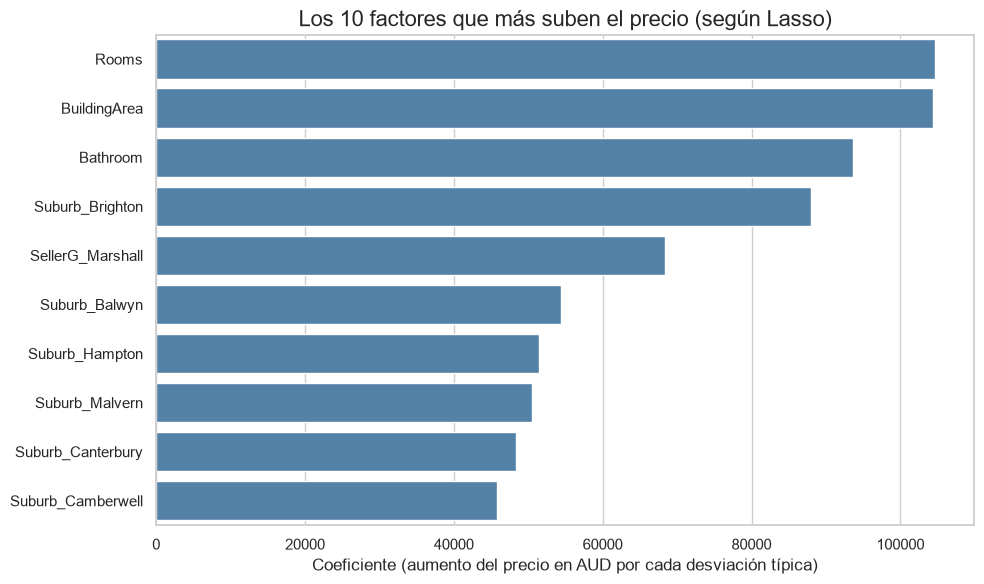

In [12]:
# 1. Coeficientes del Lasso en una Series, indexada por nombre de variable
coefs = pd.Series(lasso_cv.coef_, index=columnas_r)

# 2. Cuántos coeficientes son cero
n_ceros = (coefs == 0).sum()
print(f"Coeficientes a cero: {n_ceros} de {len(coefs)}")

# 3. Qué ha pasado con las 5 variables de ruido
es_ruido = coefs.index.str.startswith("ruido_")   # máscara booleana: True solo en las 5 de ruido
coefs_ruido = coefs[es_ruido]                     # nos quedamos con los True
print("\nCoeficientes de las variables de ruido:")
print(coefs_ruido)
print(f"¿Las 5 de ruido están a cero? {(coefs_ruido == 0).all()}")

# 4. Variables reales que Lasso ha descartado (sin contar dummies de Suburb y SellerG, que son cientos)
coefs_reales = coefs[~es_ruido]   # ~ invierte la máscara: todas menos las de ruido
descartadas = coefs_reales[coefs_reales == 0].index.tolist()
print(f"\nVariables reales descartadas: {len(descartadas)}")
for nombre in [d for d in descartadas if not d.startswith(("Suburb_", "SellerG_"))]:
    print(f"  - {nombre}")
print(f"  + {sum(d.startswith('Suburb_') for d in descartadas)} barrios y "
      f"{sum(d.startswith('SellerG_') for d in descartadas)} inmobiliarias")

# 5. Top 10 de coeficientes positivos más grandes
top10 = coefs.sort_values(ascending=False).head(10)   # ordenada de mayor a menor

plt.figure(figsize=(10, 6))
sns.barplot(x=top10.values, y=top10.index, color="steelblue")
plt.title("Los 10 factores que más suben el precio (según Lasso)", fontsize=16)
plt.xlabel("Coeficiente (aumento del precio en AUD por cada desviación típica)")
plt.ylabel("")
plt.tight_layout()
plt.show()

### Ridge contra Lasso (ejercicio 2)

Ridge encoge todos los coeficientes pero **nunca los pone a cero exacto**; Lasso sí. Cuando dos variables miden casi lo mismo, Ridge reparte el peso y Lasso se queda con una.

In [13]:
# Coeficientes de Ridge y recuento de ceros EXACTOS (no valores pequeños)
coefs_ridge = pd.Series(ridge_cv.coef_, index=columnas_r)
print(f"Coeficientes a cero RIDGE: {(coefs_ridge == 0).sum()} de {len(coefs_ridge)}")
print(f"Coeficientes a cero LASSO: {n_ceros} de {len(coefs)}")

# Ridge encoge el ruido pero no lo anula
print("\nCoeficientes de las variables de ruido RIDGE:")
print(coefs_ridge[es_ruido])
print(f"¿Las 5 de ruido están a cero? {(coefs_ridge[es_ruido] == 0).all()}")

Coeficientes a cero RIDGE: 0 de 712
Coeficientes a cero LASSO: 204 de 712

Coeficientes de las variables de ruido RIDGE:
ruido_1   -3300.784535
ruido_2    1394.909308
ruido_3    1707.404803
ruido_4   -1064.331914
ruido_5     -45.201281
dtype: float64
¿Las 5 de ruido están a cero? False


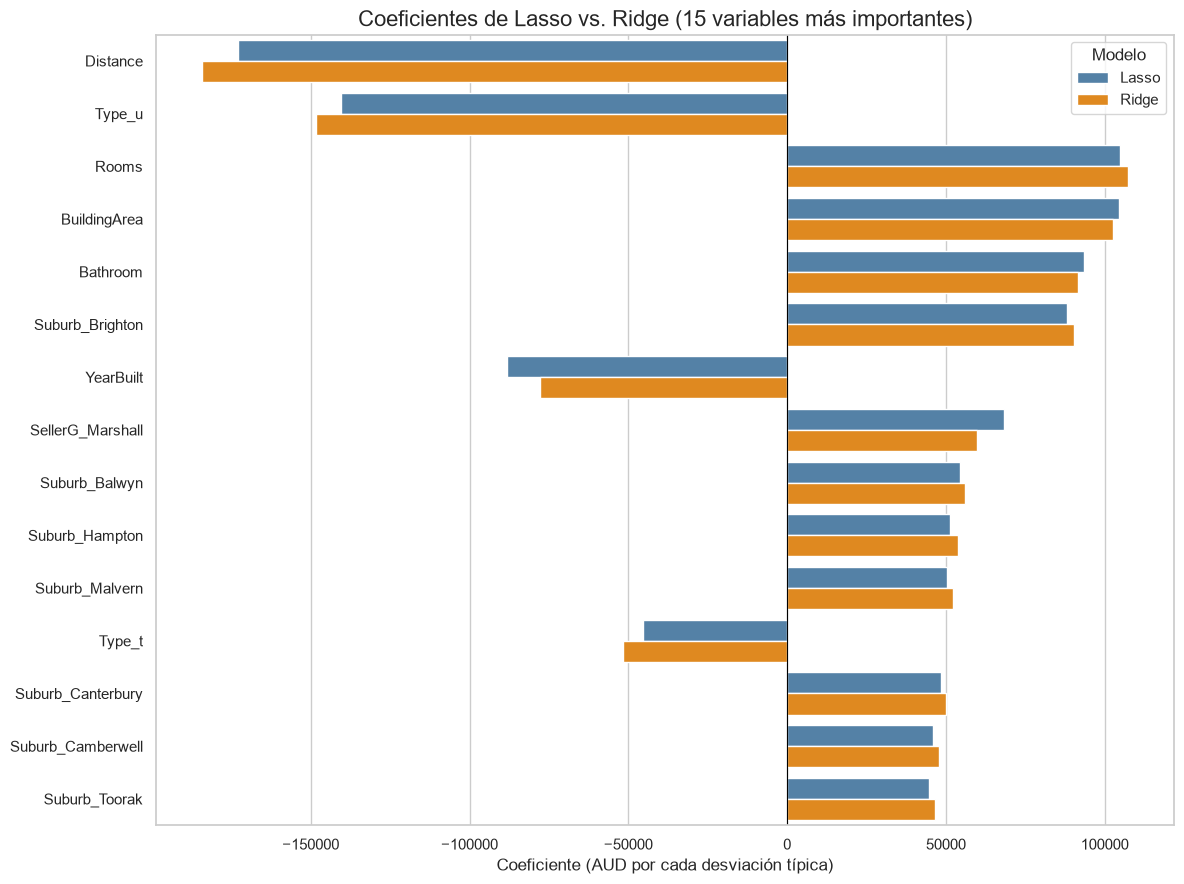

Variables que Lasso descarta pero Ridge conserva (|coef| > 9,205): 0


In [14]:
comp = pd.DataFrame({"Lasso": coefs, "Ridge": coefs_ridge})

# Las 15 variables más importantes en valor absoluto (según el mayor de los dos modelos)
top15_idx = comp.abs().max(axis=1).sort_values(ascending=False).head(15).index
top15 = comp.loc[top15_idx]

# Formato largo para el gráfico de barras agrupadas
top15_largo = (top15.reset_index().rename(columns={"index": "Variable"})
               .melt(id_vars="Variable", var_name="Modelo", value_name="Coeficiente"))

plt.figure(figsize=(12, 9))
sns.barplot(data=top15_largo, x="Coeficiente", y="Variable", hue="Modelo",
            palette={"Lasso": "steelblue", "Ridge": "darkorange"})
plt.title("Coeficientes de Lasso vs. Ridge (15 variables más importantes)", fontsize=16)
plt.xlabel("Coeficiente (AUD por cada desviación típica)")
plt.ylabel("")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

# Casos donde Lasso dice cero y Ridge mantiene un coeficiente apreciable
umbral = 0.05 * comp["Ridge"].abs().max()   # "apreciable" = al menos el 5 % del mayor coeficiente de Ridge
discrepancias = comp[(comp["Lasso"] == 0) & (comp["Ridge"].abs() > umbral)]
discrepancias = discrepancias.reindex(discrepancias["Ridge"].abs().sort_values(ascending=False).index)
print(f"Variables que Lasso descarta pero Ridge conserva (|coef| > {umbral:,.0f}): {len(discrepancias)}")

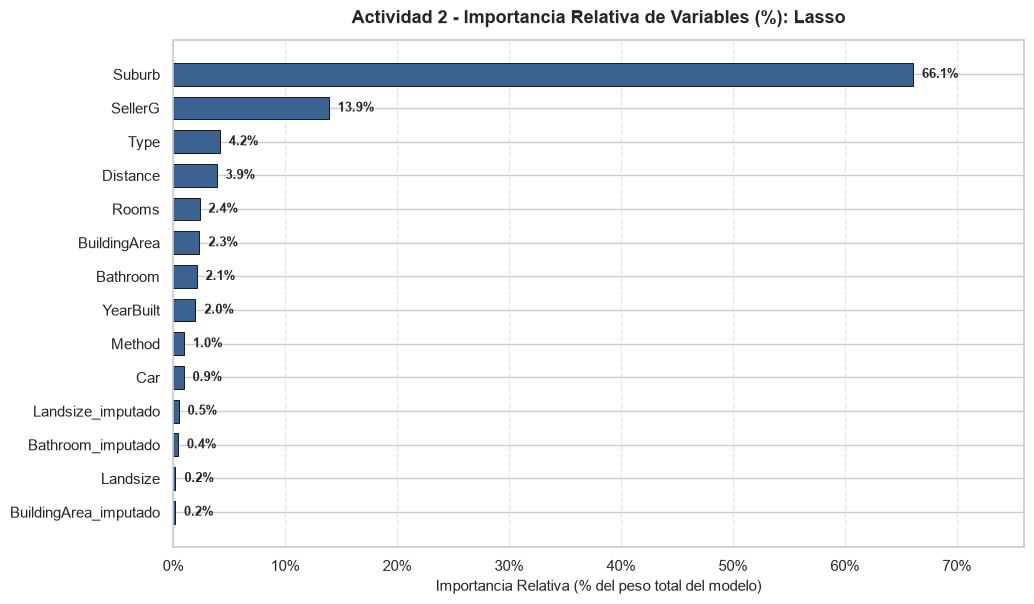

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# --- GRAFICO UNIFICADO ACTIVIDAD 2: IMPORTANCIA RELATIVA DE VARIABLES (%) ---
imp_lasso = coefs[~coefs.index.str.startswith("ruido_")].abs()
imp_lasso.index = [
    c.split("_")[0] if c.split("_")[0] in ["Type", "Suburb", "Method", "SellerG"] else c
    for c in imp_lasso.index
]
imp_lasso = imp_lasso.groupby(level=0).sum()
imp_lasso = (100 * imp_lasso / imp_lasso.sum()).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10.5, 6.2))
barras = ax.barh(imp_lasso.index, imp_lasso.values, color="#3b6291", height=0.68, edgecolor="black", linewidth=0.6)

ax.set_title("Actividad 2 - Importancia Relativa de Variables (%): Lasso", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Importancia Relativa (% del peso total del modelo)", fontsize=11)
ax.set_xlim(0, max(75, imp_lasso.max() * 1.15))
ax.xaxis.set_major_formatter(ticker.PercentFormatter(decimals=0))
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)

for barra in barras:
    ancho = barra.get_width()
    ax.text(
        ancho + 0.8,
        barra.get_y() + barra.get_height() / 2,
        f"{ancho:.1f}%",
        va="center", ha="left", fontsize=9.5, fontweight="bold"
    )

plt.tight_layout()
plt.show()

## 1.3 · ¿Qué tipo de vivienda genera más beneficio?

Sin costes en el dataset, el indicador de **beneficio** es el **precio por m² construido**, solo con viviendas cuya superficie construida es real (no imputada):
- **Bruto:** mediana de `Price / BuildingArea` por tipo.
- **Controlado:** con cada modelo, las mismas viviendas de test cambiando **solo el tipo** (misma superficie, barrio, distancia, año...). Así la diferencia no se debe a dónde están ni a cómo son.

In [15]:
# Solo viviendas de test con superficie construida real (BuildingArea_imputado = 0)
reales = X_test.index[df.loc[X_test.index, "BuildingArea_imputado"] == 0]
datos_13 = df.loc[reales].copy()
datos_13["precio_m2"] = datos_13["Price"] / datos_13["BuildingArea"]

# Indicador bruto: mediana por tipo
res_13 = datos_13.groupby("Type").agg(n=("Price", "size"), precio_mediano=("Price", "median"),
                                      m2_mediano=("BuildingArea", "median"), bruto_precio_m2=("precio_m2", "median"))

def matriz(datos):
    """Mismas columnas y escala que en el entrenamiento."""
    d = pd.get_dummies(datos.drop(columns="Price"), columns=CATEGORICAS, dtype=int)
    # reindex: añade con 0 las columnas que falten y quita las que sobren
    return scaler.transform(d.reindex(columns=columnas, fill_value=0))

for nombre in list(modelos):
    valores = {}
    for tipo in res_13.index:
        cambiado = datos_13.drop(columns="precio_m2").assign(Type=tipo)  # misma vivienda, solo cambia el tipo
        pred = modelos[nombre].predict(matriz(cambiado))
        valores[tipo] = np.median(pred / datos_13["BuildingArea"])   # precio predicho por m²
    res_13[f"controlado {nombre}"] = pd.Series(valores)

print("Tipo con mayor precio/m²:", {c: res_13[c].idxmax() for c in res_13.columns if "precio_m2" in c or "controlado" in c})
res_13.round(0)

Tipo con mayor precio/m²: {'bruto_precio_m2': 'u', 'controlado LinearRegression': 'h', 'controlado RidgeCV': 'h', 'controlado LassoCV': 'h'}


,n,precio_mediano,m2_mediano,bruto_precio_m2,controlado LinearRegression,controlado RidgeCV,controlado LassoCV
Type,,,,,,,
h,1538,1015000.0,150.0,7064.0,7887.0,7907.0,7852.0
t,187,840000.0,133.0,6487.0,6636.0,6651.0,6764.0
u,352,550500.0,76.0,7384.0,5174.0,5210.0,5331.0


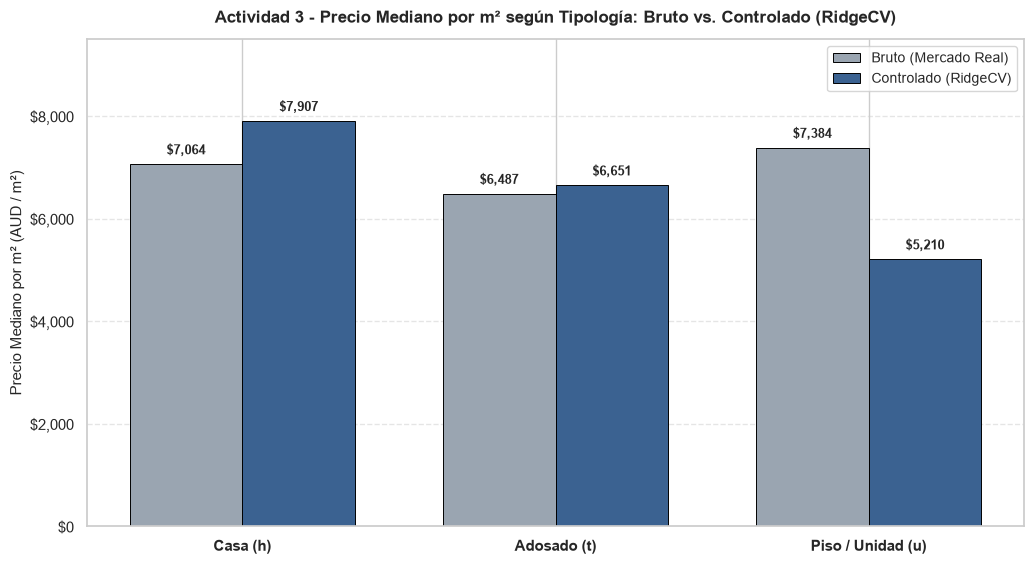

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# --- GRAFICO UNIFICADO ACTIVIDAD 3: PRECIO/M2 BRUTO VS. CONTROLADO POR TIPO ---
tipos = ["h", "t", "u"]
etiquetas = ["Casa (h)", "Adosado (t)", "Piso / Unidad (u)"]

bruto = res_13.loc[tipos, "bruto_precio_m2"].values
controlado = res_13.loc[tipos, "controlado RidgeCV"].values

x = np.arange(len(etiquetas))
ancho = 0.36

fig, ax = plt.subplots(figsize=(10.5, 5.8))
b1 = ax.bar(x - ancho/2, bruto, width=ancho, label="Bruto (Mercado Real)", color="#9aa5b1", edgecolor="black", linewidth=0.7)
b2 = ax.bar(x + ancho/2, controlado, width=ancho, label="Controlado (RidgeCV)", color="#3b6291", edgecolor="black", linewidth=0.7)

ax.set_title("Actividad 3 - Precio Mediano por m² según Tipología: Bruto vs. Controlado (RidgeCV)", fontsize=12.5, fontweight="bold", pad=12)
ax.set_ylabel("Precio Mediano por m² (AUD / m²)", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(etiquetas, fontsize=11, fontweight="bold")
ax.set_ylim(0, 9_500)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda val, _: f"${val:,.0f}"))
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)
ax.legend(frameon=True, fontsize=10, loc="upper right")

for barras in (b1, b2):
    for barra in barras:
        alto = barra.get_height()
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            alto + 140,
            f"${alto:,.0f}",
            ha="center", va="bottom", fontsize=9.5, fontweight="bold"
        )

plt.tight_layout()
plt.show()

## 1.4 · ¿Es rentable un terreno sin construir?

⚠️ No hay terrenos vacíos en el dataset. Entrenamos solo con **casas con superficie construida real** y estimamos:
- **Valor del m² construido:** cuánto sube la predicción al aumentar la superficie construida (±20 %).
- **Precio del terreno** = precio predicho de la casa − valor de lo construido.
- **Margen** = precio de mercado de la zona − terreno − coste de construir.

**Supuestos** (no salen del dataset): obra a **2.000 AUD/m²** y **15 %** de otros costes (permisos, tasas, imprevistos y venta).

In [16]:
# Supuestos (cámbialos aquí)
COSTE_M2 = 2_000                               # AUD por m² construido
OTROS_COSTES = 0.15                            # 15 % extra sobre el coste de obra
SENSIBILIDAD = [1_500, 2_000, 2_500, 3_000, 3_500]   # costes a probar en la sensibilidad

# Solo casas (Type = h) con superficie construida real
casas = df[(df["Type"] == "h") & (df["BuildingArea_imputado"] == 0)].copy()
cat_14 = ["Suburb", "Method", "SellerG"]   # Type ya no hace falta: todas son casas

# Mismo proceso que antes: dummies + escalado, ahora solo con estas casas
d14 = pd.get_dummies(casas.drop(columns=["Price", "Type"]), columns=cat_14, drop_first=True, dtype=int)
columnas_14 = list(d14.columns)
scaler_14 = StandardScaler().fit(d14)

def matriz_14(datos):
    d = pd.get_dummies(datos.drop(columns=["Price", "Type"]), columns=cat_14, dtype=int)
    return scaler_14.transform(d.reindex(columns=columnas_14, fill_value=0))

X14, y14 = matriz_14(casas), casas["Price"]

# Los mismos tres modelos lineales, entrenados solo con las casas
modelos_14 = {
    "LinearRegression": LinearRegression(),
    "RidgeCV": RidgeCV(alphas=alphas, scoring="neg_mean_squared_error"),
    "LassoCV": LassoCV(alphas=alphas, cv=5, random_state=42, max_iter=10000),
}
for m in modelos_14.values():
    m.fit(X14, y14)

# Predice con cualquiera de los tres modelos
def predecir_14(nombre, datos):
    return modelos_14[nombre].predict(matriz_14(datos))

def valor_m2(nombre, datos):
    """AUD que el modelo da a cada m² construido adicional (pendiente local, ±20 % de superficie)."""
    lo, hi = datos.copy(), datos.copy()
    lo["BuildingArea"] *= 0.8   # misma casa con un 20 % menos de superficie
    hi["BuildingArea"] *= 1.2   # ... y con un 20 % más
    # diferencia de precio / diferencia de m² = AUD por m²
    return (predecir_14(nombre, hi).mean() - predecir_14(nombre, lo).mean()) / (0.4 * datos["BuildingArea"].mean())

print(f"Casas con superficie construida real: {len(casas)}")

c:\Users\migue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.324050e+12, tolerance: 2.992e+11
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\migue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.065649e+12, tolerance: 3.301e+11
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\migue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iteration

Casas con superficie construida real: 7889


In [17]:
# Región de cada barrio (no está en el CSV limpio)
region = pd.read_csv(BASE / "datasets" / "Melbourne_housing_FULL.csv").groupby("Suburb")["Regionname"].first()
casas["Regionname"] = casas["Suburb"].map(region)

filas = []
for nombre in modelos_14:
    # Primero todas las casas juntas y después región a región
    for zona, g in [("TODAS", casas)] + list(casas.groupby("Regionname")):
        g = g.drop(columns="Regionname")   # no es una variable del modelo
        b = valor_m2(nombre, g)
        terreno = np.median(predecir_14(nombre, g) - b * g["BuildingArea"])   # precio casa - valor de lo construido
        mercado = g["Price"].median()                                          # precio de mercado de la zona
        coste = g["BuildingArea"].median() * COSTE_M2 * (1 + OTROS_COSTES)     # construir una casa típica
        margen = mercado - terreno - coste                                     # > 0 -> rentable
        filas.append({"Modelo": nombre, "Zona": zona, "n": len(g), "valor_m2_construido": b,
                      "coste_max_m2_rentable": b / (1 + OTROS_COSTES), "terreno_estimado": terreno,
                      "precio_mercado": mercado, "terreno_%_precio": 100 * terreno / mercado,
                      "coste_construccion": coste, "margen_AUD": margen,
                      "margen_%_inversion": 100 * margen / (terreno + coste)})
res_14 = pd.DataFrame(filas).set_index(["Modelo", "Zona"])
res_14.round(0)

n  valor_m2_construido  \
Modelo           Zona                                                    
LinearRegression TODAS                       7889               1450.0   
                 Eastern Metropolitan        1005               1450.0   
                 Eastern Victoria              69               1450.0   
                 Northern Metropolitan       2291               1450.0   
                 Northern Victoria             90               1450.0   
                 South-Eastern Metropolitan   438               1450.0   
                 Southern Metropolitan       1969               1450.0   
                 Western Metropolitan        1968               1450.0   
                 Western Victoria              59               1450.0   
RidgeCV          TODAS                       7889               1390.0   
                 Eastern Metropolitan        1005               1390.0   
                 Eastern Victoria              69               1390.0   
                 Northern Metropolitan       2291               1390.0   
                 Northern Victoria             90               1390.0   
                 South-Eastern Metropolitan   438               1390.0   
                 Southern Metropolitan       1969               1390.0   
                 Western Metropolitan        1968               1390.0   
                 Western Victoria              59               1390.0   
LassoCV          TODAS                       7889               1467.0   
                 Eastern Metropolitan        1005               1467.0   
                 Eastern Victoria              69               1467.0   
                 Northern Metropolitan       2291               1467.0   
                 Northern Victoria             90               1467.0   
                 South-Eastern Metropolitan   438               1467.0   
                 Southern Metropolitan       1969               1467.0   
                 Western Metropolitan        1968               1467.0   
                 Western Victoria              59               1467.0   

                                             coste_max_m2_rentable  \
Modelo           Zona                                                
LinearRegression TODAS                                      1261.0   
                 Eastern Metropolitan                       1261.0   
                 Eastern Victoria                           1261.0   
                 Northern Metropolitan                      1261.0   
                 Northern Victoria                          1261.0   
                 South-Eastern Metropolitan                 1261.0   
                 Southern Metropolitan                      1261.0   
                 Western Metropolitan                       1261.0   
                 Western Victoria                           1261.0   
RidgeCV          TODAS                                      1209.0   
                 Eastern Metropolitan                       1209.0   
                 Eastern Victoria                           1209.0   
                 Northern Metropolitan                      1209.0   
                 Northern Victoria                          1209.0   
                 South-Eastern Metropolitan                 1209.0   
                 Southern Metropolitan                      1209.0   
                 Western Metropolitan                       1209.0   
                 Western Victoria                           1209.0   
LassoCV          TODAS                                      1276.0   
                 Eastern Metropolitan                       1276.0   
                 Eastern Victoria                           1276.0   
                 Northern Metropolitan                      1276.0   
                 Northern Victoria                          1276.0   
                 South-Eastern Metropolitan                 1276.0   
                 Southern Metropolitan                      1276.0   
           

### Sensibilidad al coste de construcción

Margen % sobre la inversión (todas las zonas) según el coste por m².

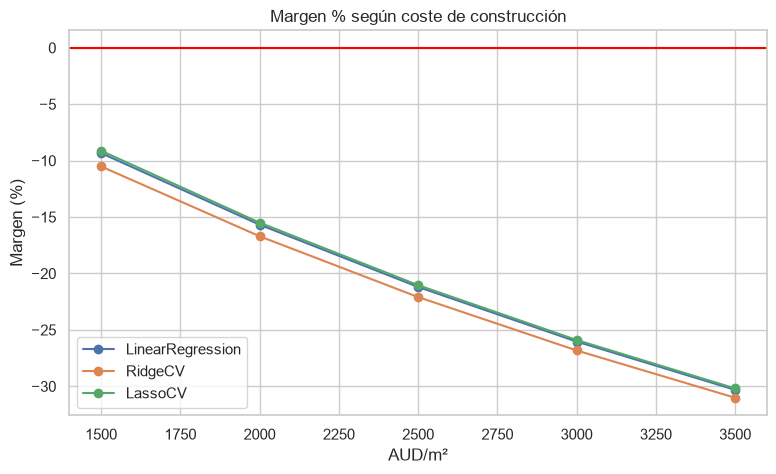

,LinearRegression,RidgeCV,LassoCV
AUD/m²,,,
1500,-9.3,-10.5,-9.1
2000,-15.7,-16.7,-15.5
2500,-21.2,-22.1,-21.0
3000,-26.0,-26.8,-25.9
3500,-30.3,-31.0,-30.2


In [18]:
todas = casas.drop(columns="Regionname")

# Mismo cálculo que arriba (todas las zonas), repetido para cada coste por m²
sens = {}
for nombre in modelos_14:
    b = valor_m2(nombre, todas)
    terreno = np.median(predecir_14(nombre, todas) - b * todas["BuildingArea"])
    mercado, area = todas["Price"].median(), todas["BuildingArea"].median()
    sens[nombre] = {c: 100 * (mercado - terreno - area * c * (1 + OTROS_COSTES))
                       / (terreno + area * c * (1 + OTROS_COSTES)) for c in SENSIBILIDAD}
sens = pd.DataFrame(sens).rename_axis("AUD/m²")

sens.plot(marker="o", figsize=(9, 5), title="Margen % según coste de construcción")
plt.axhline(0, color="red")   # por encima de la línea roja, rentable
plt.ylabel("Margen (%)")
plt.show()
sens.round(1)

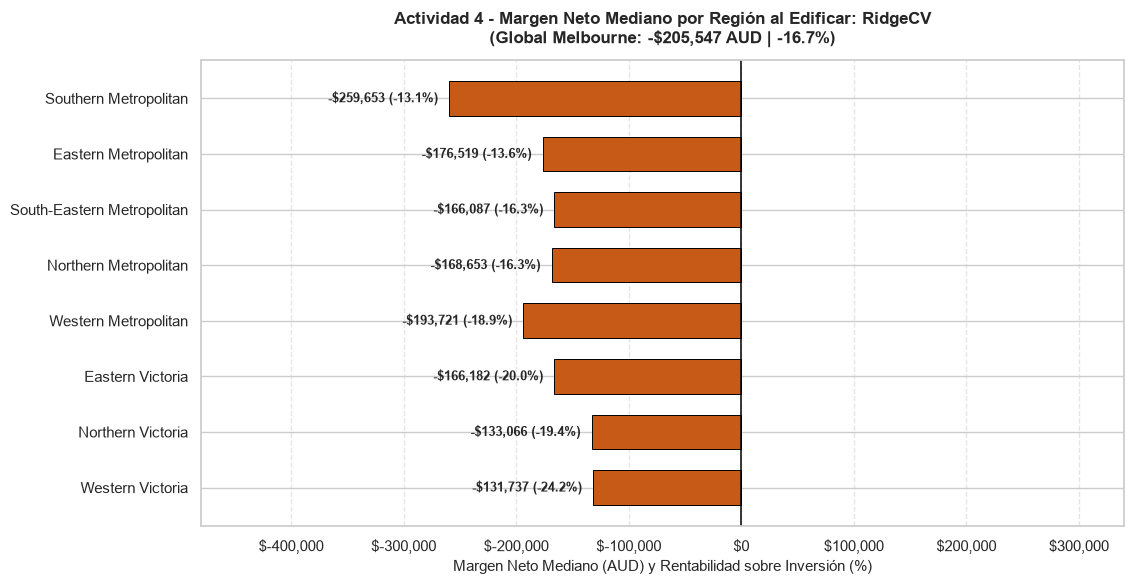

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# --- GRAFICO UNIFICADO ACTIVIDAD 4: RENTABILIDAD NETA POR REGION (AUD Y %) ---
orden_regiones = [
    "Western Victoria",
    "Northern Victoria",
    "Eastern Victoria",
    "Western Metropolitan",
    "Northern Metropolitan",
    "South-Eastern Metropolitan",
    "Eastern Metropolitan",
    "Southern Metropolitan",
]

df_reg = res_14.loc["RidgeCV"]
global_aud = df_reg.loc["TODAS", "margen_AUD"]
global_pct = df_reg.loc["TODAS", "margen_%_inversion"]

df_plot = df_reg.reindex(orden_regiones).dropna()
colores = ["#2e8b57" if val > 0 else "#c85a17" for val in df_plot["margen_AUD"]]

fig, ax = plt.subplots(figsize=(11.5, 6))
barras = ax.barh(df_plot.index, df_plot["margen_AUD"], color=colores, height=0.62, edgecolor="black", linewidth=0.7)

ax.axvline(0, color="black", linewidth=1.1)
ax.set_xlim(-480_000, 340_000)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)

ax.set_title(
    f"Actividad 4 - Margen Neto Mediano por Región al Edificar: RidgeCV\n"
    f"(Global Melbourne: {'+' if global_aud >= 0 else '-'}${abs(global_aud):,.0f} AUD | {global_pct:+.1f}%)",
    fontsize=12.5, fontweight="bold", pad=12
)
ax.set_xlabel("Margen Neto Mediano (AUD) y Rentabilidad sobre Inversión (%)", fontsize=10.5)

for barra, (_, fila) in zip(barras, df_plot.iterrows()):
    val = fila["margen_AUD"]
    pct = fila["margen_%_inversion"]
    signo = "+" if val >= 0 else "-"
    texto = f"{signo}${abs(val):,.0f} ({pct:+.1f}%)"
    offset = 10_000 if val >= 0 else -10_000
    alineacion = "left" if val >= 0 else "right"
    ax.text(
        val + offset,
        barra.get_y() + barra.get_height() / 2,
        texto,
        va="center", ha=alineacion, fontsize=9.5, fontweight="bold"
    )

plt.tight_layout()
plt.show()